# just_tx vs just_tx_hal：丢包扫速与 RTT–pps

同一块 ESP32-C3、同一 AP、同一台 TR3000。HAL / XDP 用**同一组** TR3000 发包速率扫丢包与回包 PPS；RTT 为双面板箱图（约 400–1600 / 2000–4000 pps，y 轴各自缩放）。末图 return PPS（中位 ± IQR）综合前两图：相对 $y=x$ 的掉队对应丢包，平台期对应 RTT 抬升。

| 臂 | 固件 / 冷表 | 回发路径 |
|---|---|---|
| **HAL** | `just_tx_hal` | 应用层 UDP:8080 原载荷回发 |
| **XDP** | `just_drop` 固件 + 冷表 `just_tx.elf` | Wi-Fi 入口 MAC 交换后 `XDP_TX` |

工作点：扫速各点取试次中位丢包；落在 4%–7% 内取最大 `target_pps`，否则取最接近 5% 的点。

数据：`formal.just_tx_config` / `just_tx_data`（窗长 `<15s` = sweep，`≥15s` = operating）。

**复现**（cwd = `xpost/`）：

```bash
cargo xtask agent --listen 0.0.0.0:9240 --no-monitor
```

TR3000（`default.toml` 的 `run` 含 `just_tx`）：

```bash
./xpost-test
```

本笔记只读库（`.env` 设 `PGSCHEMA=formal`）。设备侧满速处理 PPS 见 `just_drop.ipynb`。

nan@192.168.110.96:5432/postgres schema=formal
rates= [400, 800, 1200, 1600, 2000, 2400, 2800, 3200, 3600, 4000]
hal_loss%= [0.0, 0.04, 27.63, 46.87, 59.53, 68.02, 73.65, 77.45, 80.34, 82.66]
xdp_loss%= [0.0, 0.0, 0.0, 0.0, 2.46, 19.42, 36.35, 49.1, 53.06, 59.84]


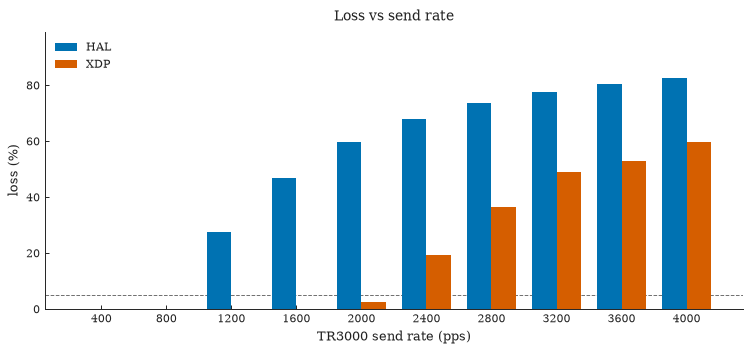

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from utils.db import dsn_summary
from utils.experiment import figure_tx_rtt_loss_vs_rate, load_just_tx_window_stats

plt.ioff()
plt.close("all")
print(dsn_summary())

sweep = load_just_tx_window_stats(phase="sweep")
assert len(sweep), "无 sweep 行：先跑 ./xpost-test（run 含 just_tx，勿加 --no-pg）"

rates = sorted(sweep["target_pps"].unique())


def _med_loss(fw: str, rate: float):
    sub = sweep[(sweep["fw_type"] == fw) & (np.isclose(sweep["target_pps"], rate))]
    if sub.empty:
        return None
    return float(sub["loss_rate"].median())


hal_loss = [_med_loss("hal", r) for r in rates]
xdp_loss = [_med_loss("xdp", r) for r in rates]
print("rates=", [int(r) for r in rates])
print("hal_loss%=", [None if v is None else round(100 * v, 2) for v in hal_loss])
print("xdp_loss%=", [None if v is None else round(100 * v, 2) for v in xdp_loss])

fig, _ = figure_tx_rtt_loss_vs_rate(
    rates_pps=rates,
    hal_loss=hal_loss,
    xdp_loss=xdp_loss,
    title="Loss vs send rate",
)
display(fig)
plt.close(fig)

nan@192.168.110.96:5432/postgres schema=formal
hal n=520289  xdp n=1067893


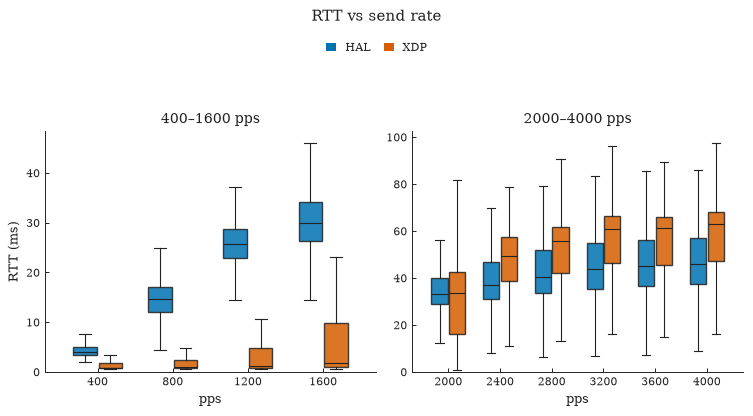

In [2]:
import matplotlib.pyplot as plt
from IPython.display import display

from utils.db import dsn_summary
from utils.experiment import figure_tx_rtt_vs_pps, load_just_tx_rtt_points

plt.ioff()
plt.close("all")
print(dsn_summary())

pts = load_just_tx_rtt_points()
assert len(pts), "无 just_tx_data 成功 RTT：先跑 ./xpost-test（run 含 just_tx）"
hal = pts[pts["fw_type"] == "hal"]
xdp = pts[pts["fw_type"] == "xdp"]
print(f"hal n={len(hal)}  xdp n={len(xdp)}")
assert len(hal) and len(xdp), "需要 HAL 与 XDP 两侧 RTT"

fig, _ = figure_tx_rtt_vs_pps(
    hal_pps=hal["target_pps"],
    hal_rtt_ms=hal["rtt_ms"],
    xdp_pps=xdp["target_pps"],
    xdp_rtt_ms=xdp["rtt_ms"],
    title="RTT vs send rate",
)
display(fig)
plt.close(fig)

nan@192.168.110.96:5432/postgres schema=formal
hal_return_pps= [368, 736, 799, 782, 744, 705, 675, 662, 649, 636]
xdp_return_pps= [368, 736, 1104, 1470, 1793, 1772, 1636, 1496, 1549, 1470]


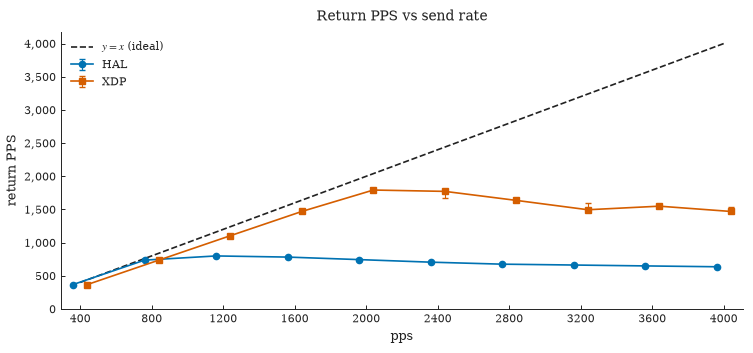

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from utils.db import dsn_summary
from utils.experiment import figure_tx_rtt_return_pps, load_just_tx_window_stats

plt.ioff()
plt.close("all")
print(dsn_summary())

sweep = load_just_tx_window_stats(phase="sweep")
assert len(sweep), "无 sweep 行：先跑 ./xpost-test（run 含 just_tx）"

rates = sorted(sweep["target_pps"].unique())


def _rpps_stats(fw: str, rate: float):
    sub = sweep[(sweep["fw_type"] == fw) & (np.isclose(sweep["target_pps"], rate))]
    if sub.empty:
        return None, None, None
    s = sub["return_pps"].astype(float)
    return float(s.median()), float(s.quantile(0.25)), float(s.quantile(0.75))


hal_stats = [_rpps_stats("hal", r) for r in rates]
xdp_stats = [_rpps_stats("xdp", r) for r in rates]
hal_rpps = [t[0] for t in hal_stats]
xdp_rpps = [t[0] for t in xdp_stats]
print("hal_return_pps=", [None if v is None else round(v) for v in hal_rpps])
print("xdp_return_pps=", [None if v is None else round(v) for v in xdp_rpps])

fig, _ = figure_tx_rtt_return_pps(
    rates_pps=rates,
    hal_return_pps=hal_rpps,
    xdp_return_pps=xdp_rpps,
    hal_return_lo=[t[1] for t in hal_stats],
    hal_return_hi=[t[2] for t in hal_stats],
    xdp_return_lo=[t[1] for t in xdp_stats],
    xdp_return_hi=[t[2] for t in xdp_stats],
    title="Return PPS vs send rate",
)
display(fig)
plt.close(fig)